# Исследовательский анализ SMS

Задание № 5 проекта SMS Guard. Анализируется весь очищенный англоязычный корпус UCI из задания № 4. Метка `ham` означает обычное SMS, `spam` — нежелательное SMS. Искусственный русско-казахский набор не используется. Анализ описательный и проводится до обучения.

In [1]:
from collections import Counter
from html import unescape
from pathlib import Path
import re

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

root = Path(".") if Path("manage.py").is_file() else Path("..")
data_path = root / "data" / "processed" / "sms_clean.csv"
figures = root / "docs" / "figures"
sms = pd.read_csv(data_path, encoding="utf-8", keep_default_na=False)
figures.mkdir(parents=True, exist_ok=True)

classes = ["ham", "spam"]
colors = ["#236c9c", "#a14126"]
sms["Класс"] = sms["label"].map({0: "ham", 1: "spam"})


def show_figure(fig, filename):
    path = figures / filename
    fig.savefig(path, dpi=150)
    plt.close(fig)
    display(Image(filename=str(path), width=800))

## Распределение классов

,Сообщений,"Доля, %"
Класс,,
ham,4517,87.96
spam,618,12.04


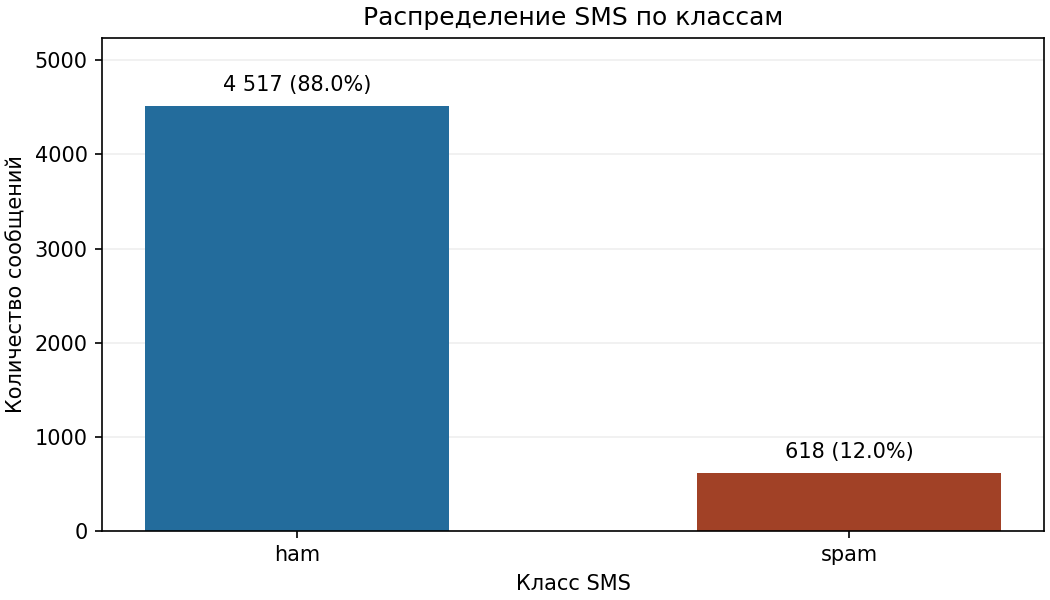

In [2]:
counts = sms["Класс"].value_counts().reindex(classes)
shares = counts / len(sms) * 100
display(pd.DataFrame({"Сообщений": counts, "Доля, %": shares.round(2)}))

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
bars = ax.bar(classes, counts, color=colors, width=0.55)
ax.bar_label(bars, labels=[f"{n:,} ({p:.1f}%)".replace(",", " ")
                           for n, p in zip(counts, shares)], padding=5)
ax.set(title="Распределение SMS по классам", xlabel="Класс SMS",
       ylabel="Количество сообщений", ylim=(0, counts.max() * 1.16))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
show_figure(fig, "01_class_distribution.png")

## Длина сообщений

Длина измеряется по `text_raw` у строк, сохранившихся после очистки. Число слов считается по последовательностям букв с возможным апострофом внутри. Гистограммы используют общие интервалы для обоих классов, доля в каждом интервале рассчитана от размера соответствующего класса.

,Медиана символов,Медиана слов
Класс,,
ham,53.0,11.0
spam,148.0,24.0


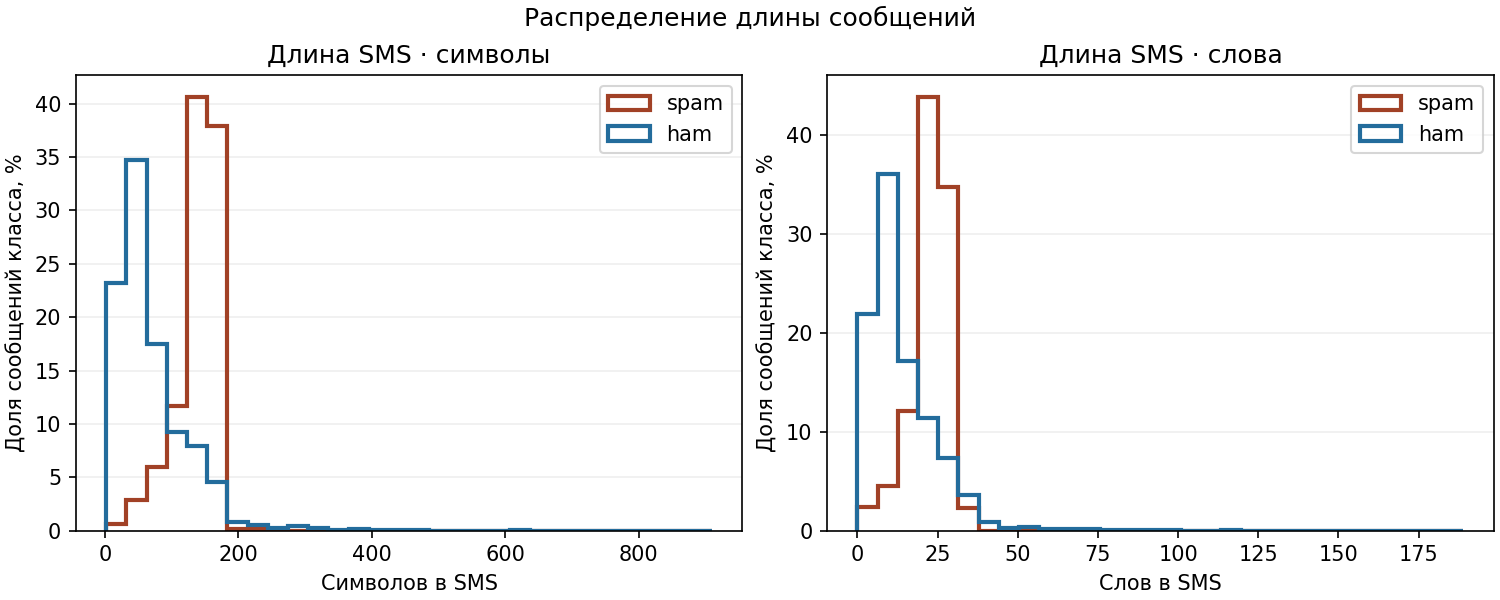

In [3]:
sms["Символы"] = sms["text_raw"].str.len()
sms["Слова"] = sms["text_raw"].str.count(r"[^\W\d_]+(?:['’][^\W\d_]+)*")
median_lengths = sms.groupby("Класс")[["Символы", "Слова"]].median().reindex(classes)
display(median_lengths.rename(columns={"Символы": "Медиана символов",
                                      "Слова": "Медиана слов"}))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, column, xlabel in zip(axes, ["Символы", "Слова"], ["Символов в SMS", "Слов в SMS"]):
    values = [sms.loc[sms["Класс"].eq(label), column] for label in classes]
    ax.hist(values, bins=30, weights=[[100 / len(group)] * len(group) for group in values],
            histtype="step", linewidth=2, label=classes, color=colors)
    ax.set(title=f"Длина SMS · {column.lower()}", xlabel=xlabel,
           ylabel="Доля сообщений класса, %")
    ax.grid(axis="y", alpha=0.2)
    ax.legend()
fig.suptitle("Распределение длины сообщений")
show_figure(fig, "02_message_lengths.png")

## Частые слова и биграммы

Подсчёт по `text_clean`. Использован встроенный английский список стоп-слов scikit-learn. HTML-сущности декодируются при подсчёте, чтобы фрагменты вроде `lt` и `gt` не считались словами. Служебные токены разрывают биграммы. В биграммы входят соседние слова одного SMS, если оба проходят фильтр. Частота означает число вхождений.

In [4]:
token_pattern = re.compile(r"<[a-z]+>|[a-z]+(?:['’][a-z]+)*")
word_counts = {}
bigram_counts = {}

for label in classes:
    words = Counter()
    bigrams = Counter()
    for text in sms.loc[sms["Класс"].eq(label), "text_clean"]:
        tokens = token_pattern.findall(unescape(text))
        keep = [not token.startswith("<") and token not in ENGLISH_STOP_WORDS
                for token in tokens]
        words.update(token for token, valid in zip(tokens, keep) if valid)
        bigrams.update(
            f"{first} {second}"
            for first, second, first_valid, second_valid in
            zip(tokens, tokens[1:], keep, keep[1:])
            if first_valid and second_valid
        )
    word_counts[label] = words
    bigram_counts[label] = bigrams

for heading, frequencies in [("Топ-20 слов", word_counts), ("Топ-20 биграмм", bigram_counts)]:
    display(Markdown(f"### {heading}"))
    tables = {
        label: pd.DataFrame(frequencies[label].most_common(20),
                            columns=["Выражение", "Частота"], index=range(1, 21))
        for label in classes
    }
    display(pd.concat(tables, axis=1).rename_axis("Место"))

### Топ-20 слов

ham              spam        
      Выражение Частота Выражение Частота
Место                                    
1             u     925      free     189
2           i'm     370         p     147
3          just     282         u     137
4            ok     256       txt     133
5           got     228      stop     116
6          know     226        ur     115
7          like     224      text     107
8          good     217    mobile     104
9          come     215     reply      95
10           ur     203     claim      88
11         time     187     prize      72
12         love     185      just      65
13          day     184      cash      62
14        going     164       new      62
15         want     162         t      60
16          lor     159      send      59
17         home     156     nokia      55
18         need     155       won      53
19           da     142    urgent      52
20            k     138       msg      51

### Топ-20 биграмм

ham                      spam        
          Выражение Частота         Выражение Частота
Место                                                
1               r u      35              t cs      26
2               u r      33            po box      24
3               k k      26             p min      24
4      good morning      24         contact u      22
5             u wan      23         send stop      18
6             did u      22             p msg      17
7         i'm going      21  prize guaranteed      16
8          new year      21          txt stop      15
9          just got      20     national rate      15
10           ok lor      19  await collection      15
11            hi hi      18        nd attempt      14
12         wat time      18        free entry      13
13        happy new      17               t c      13
14       good night      16           ur cash      13
15        great day      16    dating service      13
16        dont know      16        ur awarded      12
17        i'm gonna      15        draw shows      12
18              c u      14      caller prize      12
19            u dun      13         land line      12
20       don't know      13      bonus caller      11

## Признаки в сообщениях

Сообщение учитывается один раз для каждого признака, даже если признак встречается в нём несколько раз. Признаки проверяются по `text_clean`.

Сообщений      Доля, %       
Класс         ham spam     ham   spam
Признак                              
<url>          11  114    0.24  18.45
<phone>         1  286    0.02  46.28
<money>        12  205    0.27  33.17
!             530  291   11.73  47.09

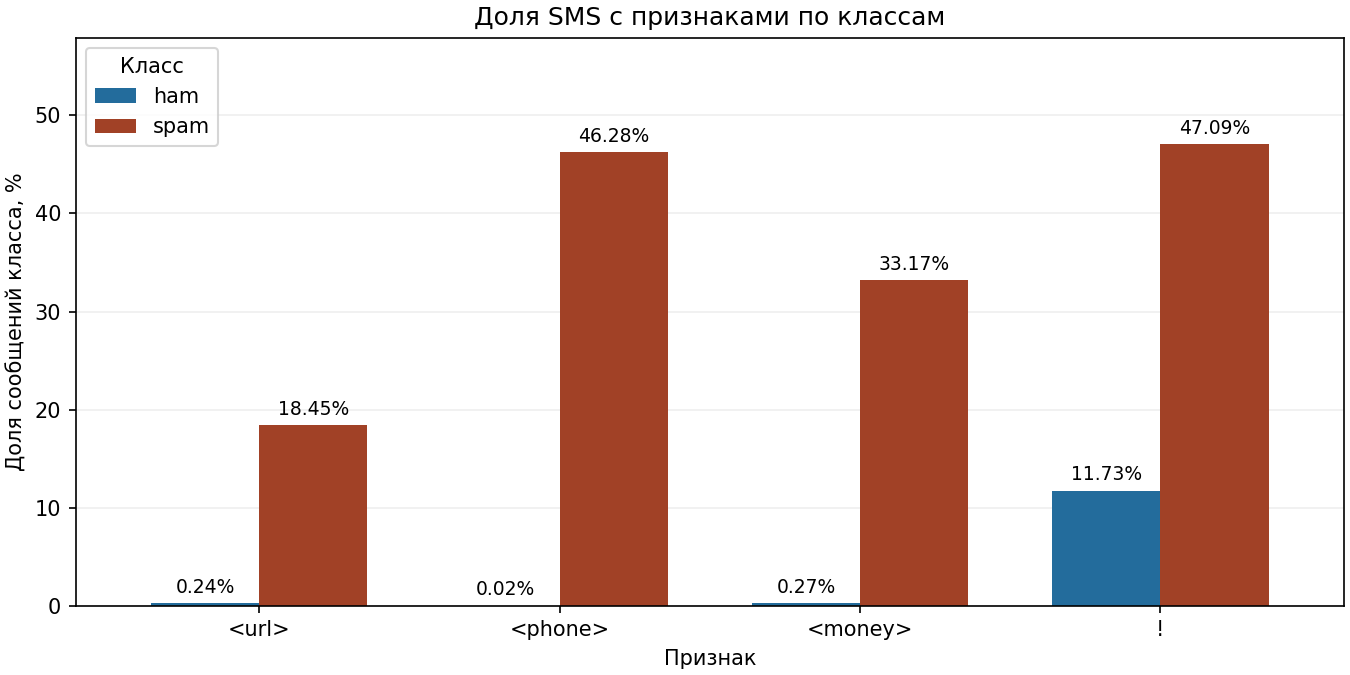

In [5]:
markers = ["<url>", "<phone>", "<money>", "!"]
presence = pd.DataFrame({
    marker: sms["text_clean"].str.contains(marker, regex=False) for marker in markers
})
marker_counts = presence.groupby(sms["Класс"]).sum().reindex(classes).T
marker_shares = marker_counts.div(counts, axis="columns") * 100
display(pd.concat({"Сообщений": marker_counts, "Доля, %": marker_shares.round(2)}, axis=1)
        .rename_axis("Признак"))

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
marker_shares.plot.bar(ax=ax, color=colors, rot=0, width=0.72)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=9)
ax.set(title="Доля SMS с признаками по классам", xlabel="Признак",
       ylabel="Доля сообщений класса, %", ylim=(0, marker_shares.max().max() * 1.23))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(title="Класс")
show_figure(fig, "03_marker_shares.png")

In [6]:
def percent(value):
    return f"{value:.2f}".replace(".", ",") + "%"


def compare_marker(marker):
    return (f"{marker_counts.loc[marker, 'spam']} из {counts['spam']} spam "
            f"({percent(marker_shares.loc[marker, 'spam'])}) и "
            f"{marker_counts.loc[marker, 'ham']} из {counts['ham']} ham "
            f"({percent(marker_shares.loc[marker, 'ham'])})")


spam_word, spam_word_count = word_counts["spam"].most_common(1)[0]
ham_word, ham_word_count = word_counts["ham"].most_common(1)[0]
spam_bigram, spam_bigram_count = bigram_counts["spam"].most_common(1)[0]
ham_bigram, ham_bigram_count = bigram_counts["ham"].most_common(1)[0]

display(Markdown(f"""
## Выводы

1. **Классы несбалансированы.** Ham — {counts['ham']} SMS ({percent(shares['ham'])}), spam — {counts['spam']} ({percent(shares['spam'])}). Предсказание только ham дало бы accuracy {percent(shares['ham'])} при полноте spam 0%. В следующих заданиях будем применять стратифицированное разбиение, смотреть precision, recall, F1 и PR-AUC для spam и при необходимости использовать параметр `class_weight` у поддерживающих его моделей.
2. **Spam длиннее по медиане.** У spam медиана составляет {median_lengths.loc['spam', 'Символы']:.0f} символов и {median_lengths.loc['spam', 'Слова']:.0f} слова. У ham — {median_lengths.loc['ham', 'Символы']:.0f} символа и {median_lengths.loc['ham', 'Слова']:.0f} слов.
3. **Контактные данные чаще отмечены в spam.** Токен `<phone>` встречается в {compare_marker('<phone>')}. Токен `<url>` — в {compare_marker('<url>')}.
4. **Денежные суммы и восклицания различаются по частоте.** Токен `<money>` встречается в {compare_marker('<money>')}. Восклицательный знак — в {compare_marker('!')}.
5. **Лидеры по словам различаются.** В spam чаще всего встречается `{spam_word}` ({spam_word_count} вхождений), в ham — `{ham_word}` ({ham_word_count}).
6. **Лидеры по биграммам тоже различаются.** Для spam это `{spam_bigram}` ({spam_bigram_count} вхождений), для ham — `{ham_bigram}` ({ham_bigram_count}).
"""))


## Выводы

1. **Классы несбалансированы.** Ham — 4517 SMS (87,96%), spam — 618 (12,04%). Предсказание только ham дало бы accuracy 87,96% при полноте spam 0%. В следующих заданиях будем применять стратифицированное разбиение, смотреть precision, recall, F1 и PR-AUC для spam и при необходимости использовать параметр `class_weight` у поддерживающих его моделей.
2. **Spam длиннее по медиане.** У spam медиана составляет 148 символов и 24 слова. У ham — 53 символа и 11 слов.
3. **Контактные данные чаще отмечены в spam.** Токен `<phone>` встречается в 286 из 618 spam (46,28%) и 1 из 4517 ham (0,02%). Токен `<url>` — в 114 из 618 spam (18,45%) и 11 из 4517 ham (0,24%).
4. **Денежные суммы и восклицания различаются по частоте.** Токен `<money>` встречается в 205 из 618 spam (33,17%) и 12 из 4517 ham (0,27%). Восклицательный знак — в 291 из 618 spam (47,09%) и 530 из 4517 ham (11,73%).
5. **Лидеры по словам различаются.** В spam чаще всего встречается `free` (189 вхождений), в ham — `u` (925).
6. **Лидеры по биграммам тоже различаются.** Для spam это `t cs` (26 вхождений), для ham — `r u` (35).
